# Lung9 Rep1: spatial gene programs

This tutorial connects spatial topics to representative genes and original cell annotations, then examines marker-supported hypoxia-associated and proliferation-associated candidates within Tumor cells.

Install stOTopic and follow [data setup](README.md) before running.

## 1. Input

In [1]:
from pathlib import Path
import os
import anndata as ad
import pandas as pd
import torch
from IPython.display import display, Image
from stotopic import stOTopic, pp
from stotopic.demo import export_results, make_demo_data

ROOT = Path.cwd()
if ROOT.name == "tutorials":
    ROOT = ROOT.parent
os.chdir(ROOT)
torch.set_num_threads(1)
torch.set_float32_matmul_precision("high")
torch.backends.cuda.matmul.allow_tf32 = True
device = "cuda" if torch.cuda.is_available() else "cpu"


In [2]:
input_path = Path(os.environ.get("STOTOPIC_DEMO_INPUT", str(ROOT / "data" / "Lung9_Rep1.h5ad")))
if not input_path.is_file():
    raise FileNotFoundError("Prepare Lung9_Rep1.h5ad as described in tutorials/README.md")
raw = ad.read_h5ad(input_path)
output = Path("outputs/lung_tutorial")
cell_type_key = "cell_type"
print("Raw counts:", raw.shape)
print("Spatial coordinates:", raw.obsm["spatial"].shape)


Raw counts: (87606, 960)
Spatial coordinates: (87606, 2)


## 2. Prepare spatial representations

Counts remain unchanged for fitting. A separate normalized representation is propagated with SGCN and reduced by PCA.

In [3]:
parameters = {
    "num_topics": 20, "n_components": 400, "gene_selection": "all",
    "use_sgc": True, "sgc_mode": "sign", "sgc_layers": 1,
    "ct_alpha": 13.0, "tg_alpha": 1.3, "learning_rate": 0.01,
    "theta_temp": 0.1, "epochs": 10000, "early_stop_threshold": 0.1,
    "patience": 5, "seed": None, "device": device,
}
selected, embeddings = pp.prepare(
    raw, gene_selection="all", n_components=400, min_counts=50,
    use_sgc=True, sgc_layers=1, sgc_mode="sign", random_state=None,
)
print("Prepared counts:", selected.shape)


Prepared counts: (77391, 960)


## 3. Fit and export model outputs

In [4]:
model = stOTopic(20, CT_alpha=13.0, TG_alpha=1.3, theta_temp=0.1, device=device)
theta = model.fit_transform(
    selected, cell_embeddings=embeddings, use_highly_variable=False,
    epochs=10000, learning_rate=0.01, early_stop_threshold=0.1, patience=5,
)
result = export_results(
    selected, model, theta, output, cell_type_key=cell_type_key,
    focus_cell_type="Tumor", parameters=parameters,
)
print("theta (cells x topics):", result["theta"].shape)
print("beta (genes x topics):", result["beta"].shape)
display(result["theta"].iloc[:5, :5])
display(result["beta"].iloc[:5, :5])


theta (cells x topics): (77391, 20)
beta (genes x topics): (960, 20)


,Topic1,Topic2,Topic3,Topic4,Topic5
c_5_1_2,0.055413,0.031350,0.072046,0.028014,0.020662
c_5_1_7,0.120158,0.026780,0.049140,0.001344,0.003955
c_5_1_8,0.105089,0.041112,0.026847,0.009978,0.016193
c_5_1_9,0.025655,0.040872,0.122977,0.041570,0.018894
c_5_1_10,0.003219,0.007517,0.117754,0.071501,0.100140


,Topic1,Topic2,Topic3,Topic4,Topic5
AATK,0.001616,0.001057,0.001073,0.000335,0.000424
ABL1,0.000374,0.000868,0.001252,0.000711,0.001224
ABL2,0.000763,0.000584,0.001189,0.000884,0.000938
ACE,0.001172,0.000554,0.001492,0.000498,0.000393
ACE2,0.001355,0.000890,0.001291,0.000328,0.000419


## 4. Representative genes

All topics have a ranked gene table. The figure shows up to six selected topics; program candidates are included when supported.

,top_genes
topic,
Topic1,"[TPSB2, TPSAB1, CSF2RA, VSIR, RGS2, IL2RA, CPA3, IL18, LAIR1, TLR2]"
Topic2,"[SERPINA1, DMBT1, KRT7, LTF, CXCL2, FOS, GADD45B, DUSP1, ZFP36, ITGB6]"
Topic3,"[FGFR1, MECOM, WNT7A, EPHA4, NOTCH3, DDR1, DNMT3A, BMP7, KRT5, ESR1]"
Topic4,"[SOX4, ALCAM, JUNB, ETV5, JAG1, VIM, BCL2, RPL21, HSP90B1, SPRY4]"
Topic5,"[HMGB2, UBE2C, H4C3, EZH2, CALM2, TOP2A, H2AZ1, BIRC5, PTTG1, STMN1]"
Topic6,"[TAGLN, TPM2, ACTA2, COL11A1, COL9A2, ACTG2, INHBA, ADGRG2, MYH11, MEG3]"
Topic7,"[GNLY, IL7R, CCL5, CD2, BTG1, IL32, PTPRC, CD53, PTPRCAP, RUNX3]"
Topic8,"[PSAP, GLUL, HLA-DRB1, C1QC, CD74, SPP1, C1QA, CD163, CD68, HLA-DRB5]"
Topic9,"[NPPC, KRT16, COL9A2, DUSP5, WIF1, CTSG, CRP, SNAI1, PTGDR2, REG1A]"


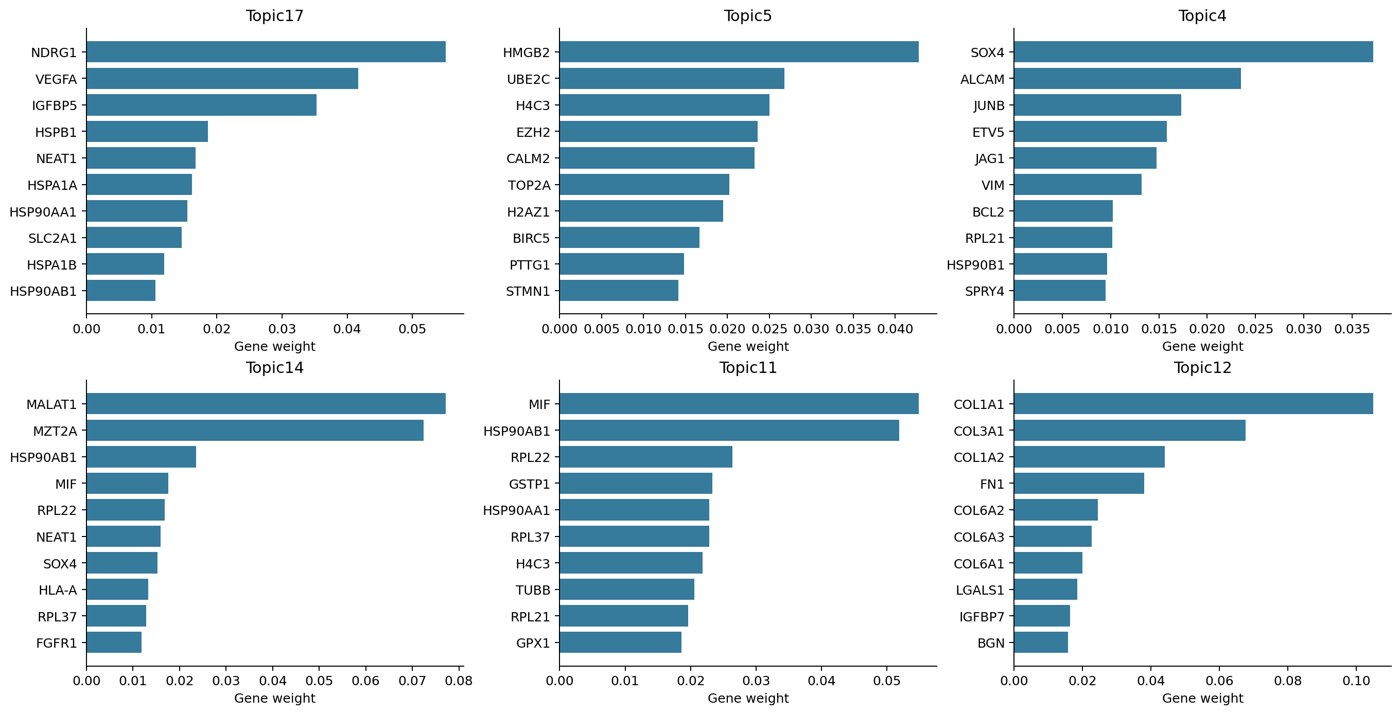

In [5]:
def show_panel(name):
    path = output / "figures" / (name + ".png")
    if "figures/" + name + ".png" in result["run_config"]["figures"]:
        display(Image(filename=str(path), width=1000))
    else:
        print("Panel unavailable for this run:", name)
display(result["top_genes"].groupby("topic", sort=False)["gene"].apply(list).to_frame("top_genes"))
show_panel("topic_genes")


## 5. Topic weights

Mean topic proportions summarize program contribution across cells. They are not cell-type abundance estimates.

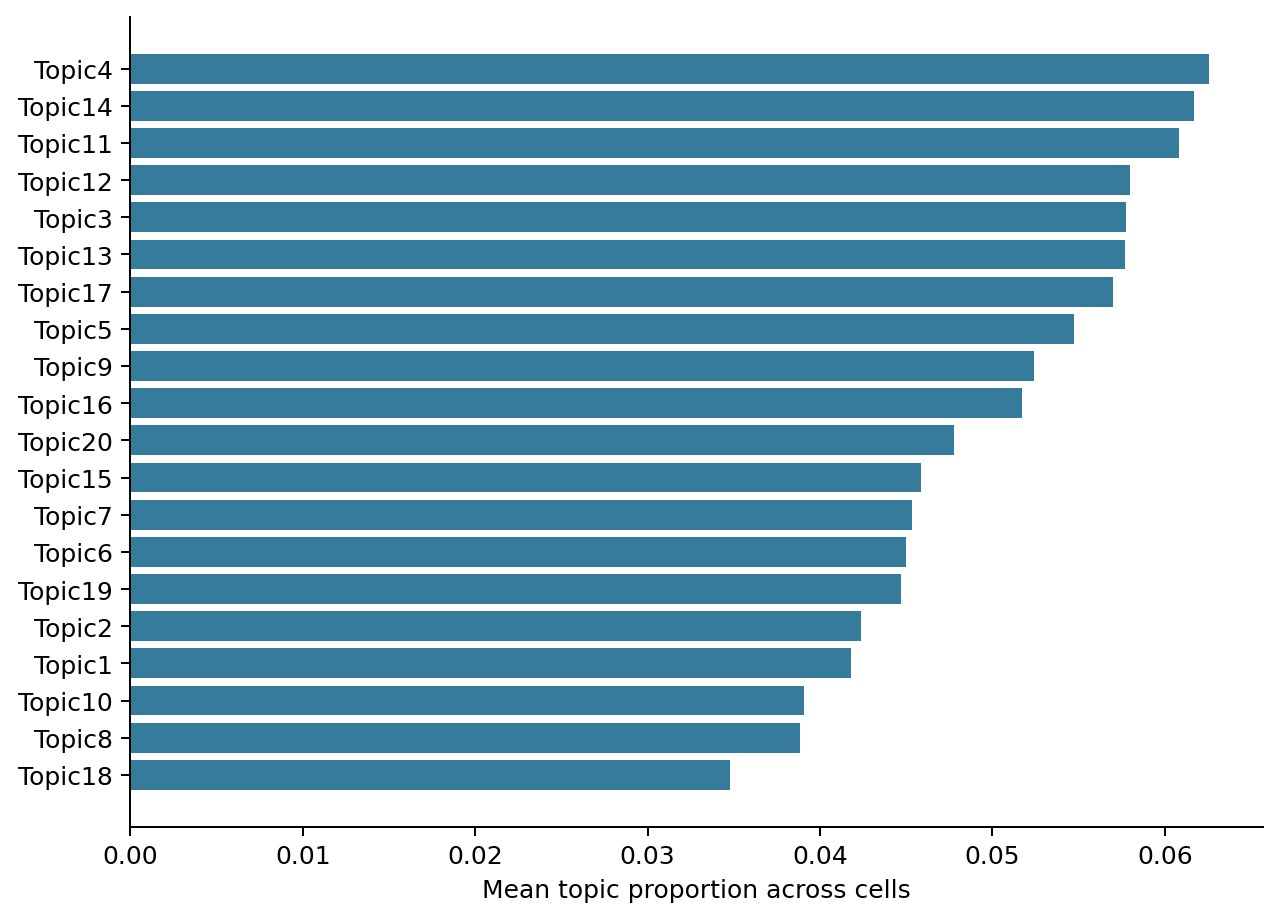

In [6]:
show_panel("topic_weights")


## 6. Spatial topics and original annotations

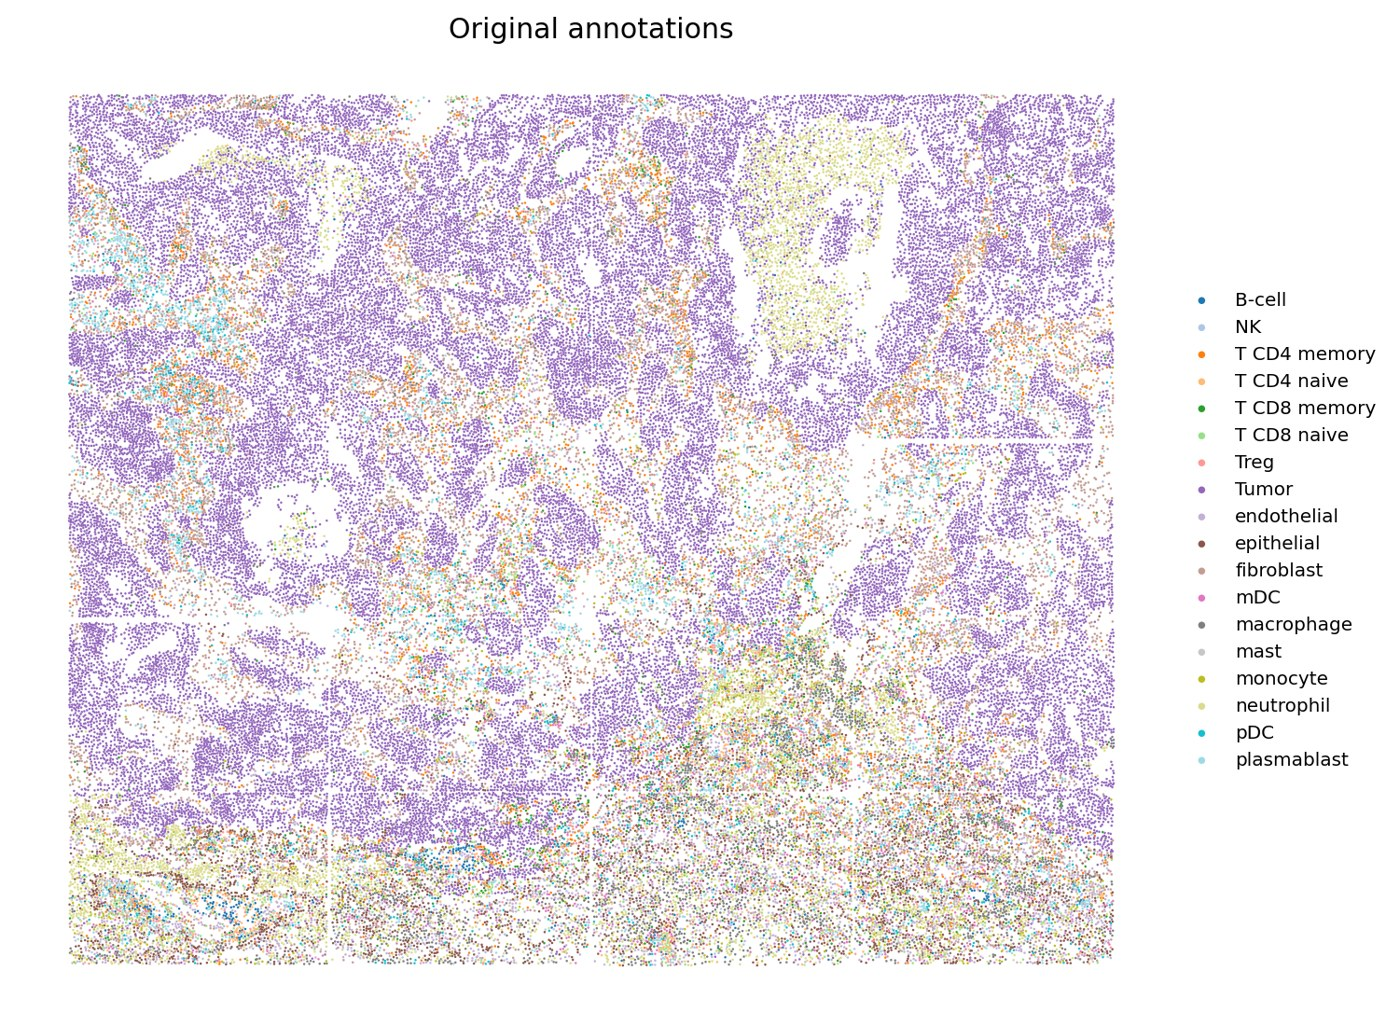

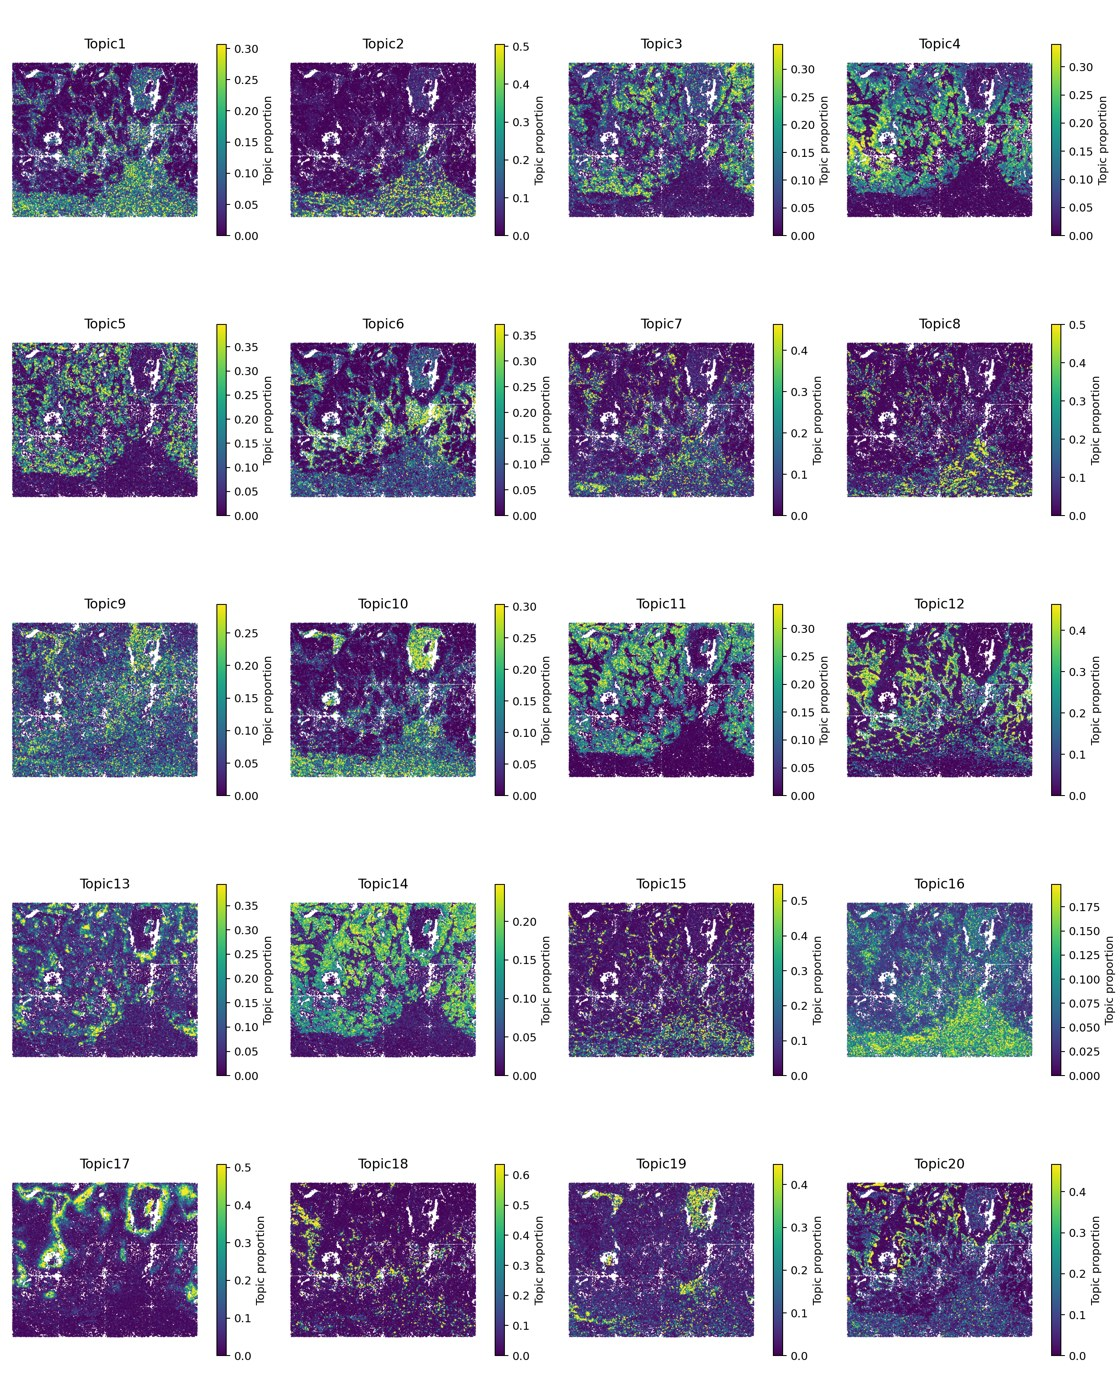

In [7]:
show_panel("cell_types")
show_panel("topic_spatial")


## 7. Examine candidate tumor programs

Hypoxia-associated markers include *NDRG1*, *VEGFA*, *SLC2A1* and *HILPDA*; proliferation-associated markers include *MKI67*, *TOP2A*, *UBE2C* and *CENPF*. 

Gene-expression panels use log1p library-normalized counts over the selected panel. Violin plots show continuous topic proportions within the original Tumor annotation. 

,program,topic,matched_markers,status
0,Hypoxia-associated,Topic17,"[NDRG1, VEGFA, IGFBP5, SLC2A1, HILPDA]",marker_supported_candidate
1,Proliferation-associated,Topic5,"[UBE2C, TOP2A, BIRC5, PTTG1, CENPF, MKI67, TYMS]",marker_supported_candidate


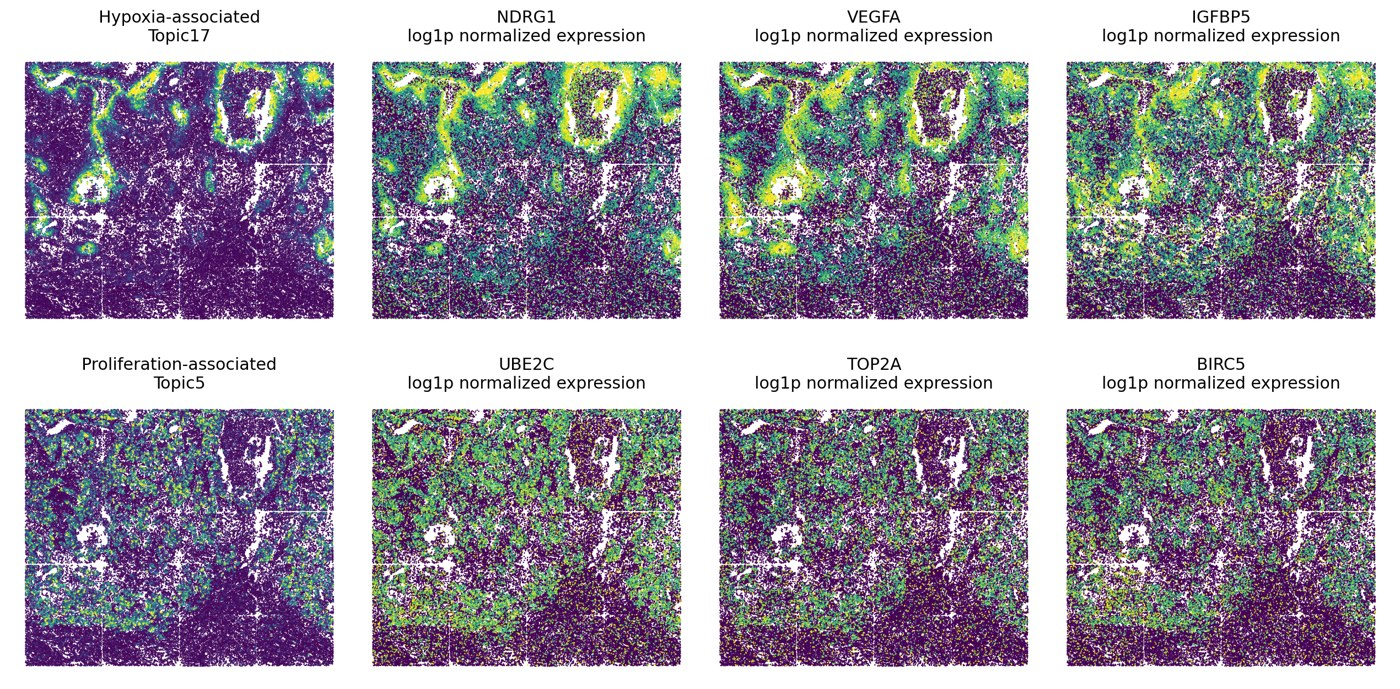

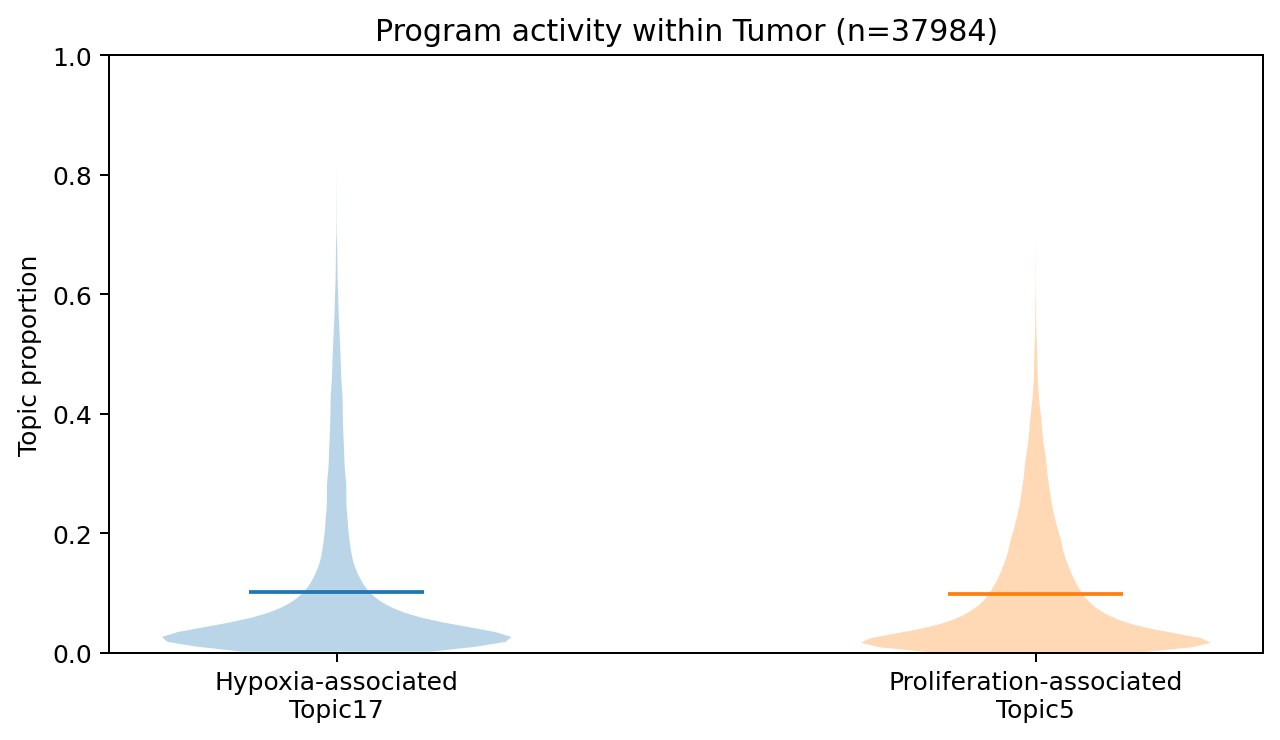

In [8]:
candidates = result["run_config"]["program_candidates"]
display(pd.DataFrame(candidates)[["program", "topic", "matched_markers", "status"]])
show_panel("program_markers")
show_panel("program_activity")
for note in result["run_config"]["notes"]:
    print(note)


## Save and reuse

The directory includes cell_topic.csv.gz, topic_gene.csv.gz, top_genes.csv, topic_summary.csv, run_config.json, an overview README, and figures. The full matrices preserve identifiers.

In [9]:
print("Saved under:", output)
display(result["topic_summary"].head())


Saved under: outputs\lung_tutorial


,topic,mean_proportion,dominant_cells,top_genes
0,Topic1,0.041812,2596,"TPSB2, TPSAB1, CSF2RA, VSIR, RGS2, IL2RA, CPA3, IL18, LAIR1, TLR2"
1,Topic2,0.042383,3700,"SERPINA1, DMBT1, KRT7, LTF, CXCL2, FOS, GADD45B, DUSP1, ZFP36, ITGB6"
2,Topic3,0.057740,4822,"FGFR1, MECOM, WNT7A, EPHA4, NOTCH3, DDR1, DNMT3A, BMP7, KRT5, ESR1"
3,Topic4,0.062569,6130,"SOX4, ALCAM, JUNB, ETV5, JAG1, VIM, BCL2, RPL21, HSP90B1, SPRY4"
4,Topic5,0.054744,5708,"HMGB2, UBE2C, H4C3, EZH2, CALM2, TOP2A, H2AZ1, BIRC5, PTTG1, STMN1"
